In [2]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.optimize
from scipy import optimize, signal
import tqdm
from matplotlib.colors import hsv_to_rgb

In [5]:
def getFilterParameters(fs, f0, quality=1, filterType=""):
    omega0 = np.pi * 2 * f0 / fs
    alpha = np.sin(omega0 / (2 * quality))
    b = np.zeros(3)
    a = np.zeros(3)
    if filterType == 'bp':
        b[0] = quality * alpha
        b[1] = 0
        b[2] = -quality * alpha
        a[0] = 1 + alpha
        a[1] = -2 * np.cos(omega0)
        a[2] = 1 - alpha
    elif filterType == "hp":
        b[0] = (1 + np.cos(omega0)) / 2
        b[1] = -(1 + np.cos(omega0))
        b[2] = (1 + np.cos(omega0)) / 2
        a[0] = 1 + alpha
        a[1] = -2 * np.cos(omega0)
        a[2] = 1 - alpha
    else:
        raise ValueError('unimplemented filterType ' + filterType)
    b /= a[0]
    a /= a[0]
    return a, b

class Filter:
    def __init__(self, fs, f0, quality=2, filterType=""):
        self.a, self.b = getFilterParameters(fs, f0, quality, filterType)
        self.input = np.zeros(3)
        self.output = np.zeros(3)

    def advance(self, input, output):
        self.input = np.roll(self.input, 1)
        self.output = np.roll(self.output, 1)
        self.input[0] = input
        self.output[0] = output

    def getPriorState(self):
        return np.sum(self.b[1:] * self.input[:-1]) - np.sum(self.a[1:] * self.output[:-1])

    def getScalingOnInput(self):
        return self.b[0]

    def process(self, x):
        self.input = np.roll(self.input, 1)
        self.output = np.roll(self.output, 1)
        self.input[0] = x
        self.output[0] = np.sum(self.b * self.input) - np.sum(self.a[1:] * self.output[1:])
        return self.output[0]

In [15]:
class NaiveFeedbackSystem:
    def __init__(self):
        self.filter = None
        self.filter_output = None
        self.filter_input = None
        self.distortion_output = None
        self.filter_frequency = 10
        self.fs = 44100
        self.filter_cv = 0
        self.gain = 2
        self.morph = 0

    def distortion_fuction(self, x):
        return max(1-2*self.morph, 0) * np.tanh(x) + min(2*self.morph, 1) * np.sin(x - np.pi * max(0, 2*self.morph-1))

    def distortion_function_derivative(self, x):
        return (max(1-2*self.morph, 0) * (1 - np.square(np.tanh(x))) +
                min(2*self.morph, 1) * np.cos(x - np.pi * max(0, 2*self.morph-1)))

    def distortion_function_second_derivative(self, x):
        return (-max(1-2*self.morph, 0) * (1 - np.square(np.tanh(x))) * 2 * np.tanh(x) +
                -min(2*self.morph, 1) * np.sin(x - np.pi * max(0, 2*self.morph-1)))

    def prepare(self):
        self.filter = Filter(self.fs, self.filter_frequency, filterType='hp')

    def _process_step(self, i, x):
        self.filter_input[i] = self.distortion_output[i-1] + x
        self.filter_output[i] = self.filter.getPriorState() + self.filter.getScalingOnInput() * self.filter_input[i]
        self.filter.advance(self.filter_input[i], self.filter_output[i])
        self.distortion_output[i] = self.distortion_fuction(self.filter_output[i] * self.gain)

    def process(self, global_x : np.ndarray):
        self.prepare()
        self.filter_input = global_x * 0
        self.filter_output = global_x * 0
        self.distortion_output = global_x * 0
        for i, x in enumerate(global_x):
            self._process_step(i, x)

In [16]:
class NewtonFeedbackSystem(NaiveFeedbackSystem):

    def _process_newton_step(self, i, x, ax=None):
        P = self.filter.getPriorState()
        b = self.filter.getScalingOnInput()
        y = self.distortion_output[i-1]
        epsilon = 1e-5
        max_iterations = 100
        tolerance = 1e-10

        # F((b(y + x) + P) * gain) - y = 0, root finding for y, code adapted from wikipedia
        f = lambda y : self.distortion_fuction((b*y + b*x + P) * self.gain) - y
        df = lambda y : self.distortion_function_derivative((b*y + b*x + P) * self.gain) * b*self.gain - 1 # chain rule

        iterates = [y]
        for _ in range(max_iterations):
            dfy = df(y)
            if abs(dfy) < epsilon:
                print("derivative too close to zero")
                break
            yNew = y - f(y) / dfy
            converged = abs(yNew - y) < tolerance
            y = yNew
            iterates.append(y)
            if converged:
                break

        if ax is not None:
            self._plot_newton_step(ax, i, f, iterates)

        self.filter_input[i] = y + x
        self.filter_output[i] = b * (y + x) + P
        self.distortion_output[i] = y
        self.filter.advance(self.filter_input[i], self.filter_output[i])

    def _plot_newton_step(self, ax, i, f, iterates):
        iterates = np.array(iterates)
        # always show the whole range tanh can reach, so that every root is visible
        lo = min(iterates.min(), -1) - 0.25
        hi = max(iterates.max(), 1) + 0.25
        ys = np.linspace(lo, hi, 2000)

        # classic Newton path: from each point on the curve, follow the tangent
        # down to y = 0 (the next iterate), then go vertically back to the curve
        fy = np.array([f(y) for y in iterates])
        path_x = np.repeat(iterates, 2)[1:]
        path_y = np.zeros_like(path_x)
        path_y[::2] = fy

        ax.axhline(0, color='#52514e', linewidth=1)
        ax.plot(ys, [f(y) for y in ys], color='#2a78d6', linewidth=2, label='F((b(y + x) + P) * gain) - y')
        ax.plot(path_x, path_y, color='#eb6834', linewidth=1, linestyle='--')
        ax.plot(iterates, fy, 'o', color='#eb6834', markersize=6, label='Newton iterates')

        # number the iterates, skipping those too close to the last labelled one to read
        last_labelled = np.inf
        for k, (y, v) in enumerate(zip(iterates, fy)):
            if abs(y - last_labelled) > 0.03 * (hi - lo):
                ax.annotate(str(k), (y, v), textcoords='offset points', xytext=(0, 8), ha='center', color='#0b0b0b')
                last_labelled = y

        ax.set_xlim(lo, hi)
        ax.set_xlabel('y')
        ax.set_title(f'Sample {i}: y = {iterates[-1]:.6f}, {len(iterates) - 1} steps')
        ax.grid(alpha=0.25)

    def _make_step_axes(self, steps, n_samples):
        # one subplot per step, in the order given; returns {step: ax}
        steps = [s for s in dict.fromkeys(np.atleast_1d(steps).tolist()) if 0 <= s < n_samples]
        if not steps:
            return {}
        ncols = min(3, len(steps))
        nrows = int(np.ceil(len(steps) / ncols))
        fig, axes = plt.subplots(nrows, ncols, figsize=(4.5 * ncols, 3.5 * nrows), squeeze=False, layout='constrained')
        axes = axes.ravel()
        for ax in axes[len(steps):]:
            ax.set_visible(False)
        return dict(zip(steps, axes))

    def process(self, global_x: np.ndarray, stepToGraph=-1):
        """stepToGraph: a sample index or list of sample indices to plot. Out-of-range indices are ignored."""
        self.prepare()
        self.filter_input = global_x * 0
        self.filter_output = global_x * 0
        self.distortion_output = global_x * 0
        step_axes = self._make_step_axes(stepToGraph, len(global_x))
        for i, x in enumerate(global_x):
            self._process_newton_step(i, x, step_axes.get(i))
        if step_axes:
            first_ax = next(iter(step_axes.values()))
            first_ax.figure.legend(*first_ax.get_legend_handles_labels(), loc='outside lower center', ncols=2)


In [17]:
def findAllZeroCrossings(f, df, interval, minSpacing, precision=1e-7):
    sub_interval_starts = [i for i in np.arange(interval[0], interval[1], minSpacing)]
    sub_interval_ends = np.append(sub_interval_starts[1:], interval[1])

    zero_crossings = []

    for int_counter in range(len(sub_interval_starts)):
        start = sub_interval_starts[int_counter]
        end = sub_interval_ends[int_counter]
        if abs(f(start)) < precision:
            zero_crossings.append(start)
        elif abs(f(end)) > precision and ((f(start) > 0) == (f(end) < 0)):
            # Start and end on opposite sides.
            sol = scipy.optimize.root_scalar(f, bracket=(start, end), fprime=df)
            if not sol.converged:
                raise ValueError("Expected convergence")
            zero_crossings.append(sol.root)

    return zero_crossings

class NewtonZonesFeedbackSystem(NewtonFeedbackSystem):
    def __init__(self):
        super().__init__()
        self.local_minmax = None

    def prepare(self):
        self.filter = Filter(self.fs, self.filter_frequency, filterType='hp')

        b = self.filter.getScalingOnInput()
        f = lambda y : self.gain * b * self.distortion_function_derivative(self.gain * b * y) - 1
        df = lambda y : np.square(self.gain*b) * self.distortion_function_derivative(self.gain * b * y)
        interval = [-self.gain * 10, self.gain * 10] # make it big just to be safe. calculate the proper interval later.
        self.local_minmax = findAllZeroCrossings(f, df, interval, 0.1) # also properly calculate the min-spacing

    def _process_newton_step(self, i, x, ax=None):
        P = self.filter.getPriorState()
        b = self.filter.getScalingOnInput()
        y = self.distortion_output[i-1]
        tolerance = 1e-10

        # F((b(y + x) + P) * gain) - y = 0, root finding for y, code adapted from wikipedia
        f = lambda y : self.distortion_fuction((b*y + b*x + P) * self.gain) - y
        df = lambda y : self.distortion_function_derivative((b*y + b*x + P) * self.gain) * b*self.gain - 1 # chain rule


        horizontalShift = b*x + P
        points = [-1] + [i - horizontalShift for i in self.local_minmax if -1 < i - horizontalShift < 1] + [1]
        starts = points[:-1]
        ends = points[1:]

        y = self.distortion_output[i-1]

        prev_region_index = 0
        for prev_region_index in range(len(starts)):
            if starts[prev_region_index] <= y <= ends[prev_region_index]:
                break

        for offset_index in range(len(starts) * 2):
            direction = 1 if offset_index % 2 else -1
            steps = offset_index // 2
            # zigzag out from the center
            region_index = direction * steps + prev_region_index
            if (0 > region_index) or (region_index >= len(starts)):
                continue

            if abs(f(starts[region_index])) < tolerance:
                y = starts[region_index]
                break

            if abs(f(ends[region_index])) < tolerance:
                y = ends[region_index]
                break

            if (f(starts[region_index]) > 0) == (f(ends[region_index]) > 0):
                continue

            sol = scipy.optimize.root_scalar(f, bracket=(starts[region_index], ends[region_index]), fprime=df)
            if not sol.converged:
                raise ValueError("Expected convergence")
            y = sol.root
            break

        self.filter_input[i] = y + x
        self.filter_output[i] = b * (y + x) + P
        self.distortion_output[i] = y
        self.filter.advance(self.filter_input[i], self.filter_output[i])


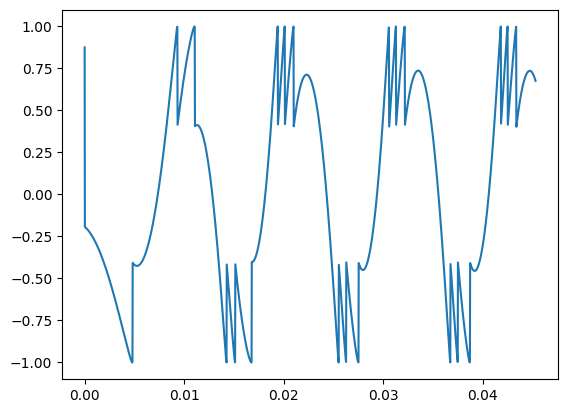

In [43]:
# for s in (NaiveFeedbackSystem(), NewtonFeedbackSystem(), NewtonZonesFeedbackSystem()):
for s in [NewtonZonesFeedbackSystem()]:
    s.gain = 8.5
    s.morph = 0.7
    s.filter_frequency = 100
    x = np.zeros(2000)
    t = np.arange(len(x)) / s.fs
    x[0] = 1
    s.process(x)
    plt.plot(t, s.filter_input)

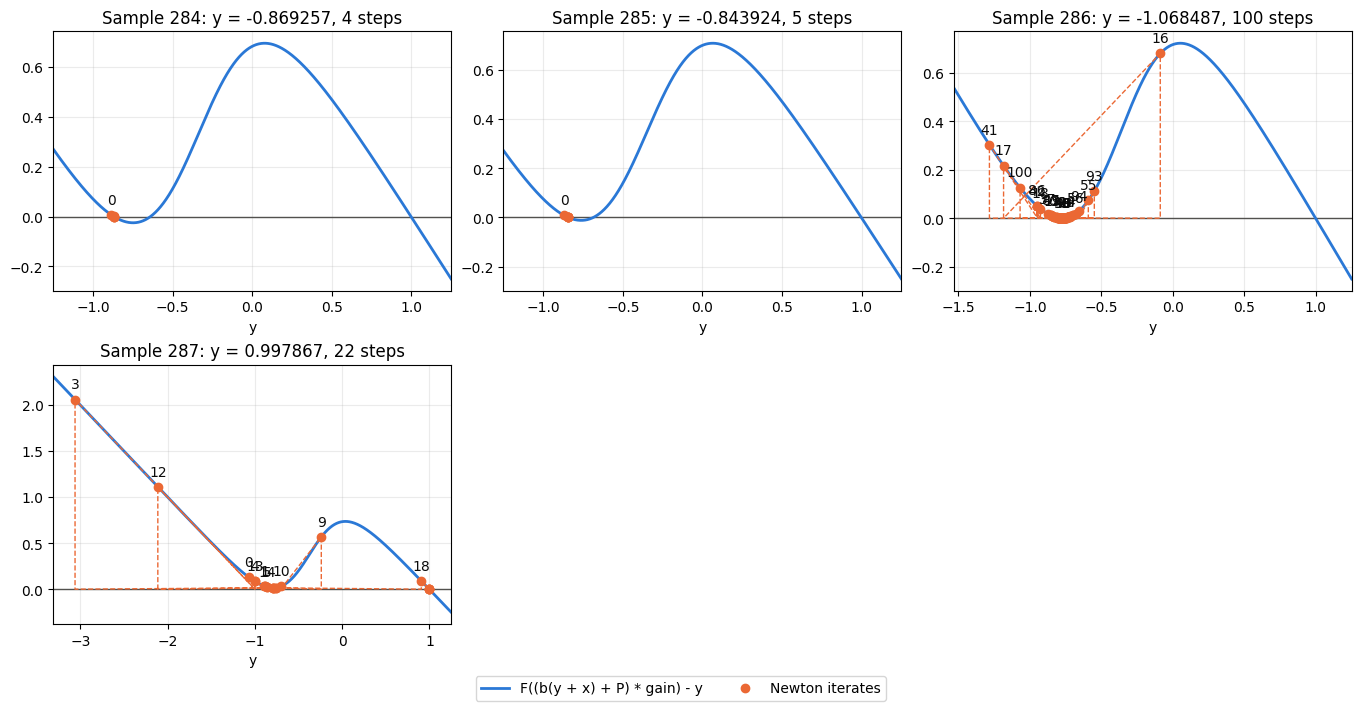

In [19]:
s = NewtonFeedbackSystem()
s.gain = 2.5
s.filter_frequency = 100
x = np.zeros(1000)
t = np.arange(len(x)) / s.fs
x[0] = 1
s.process(x, stepToGraph=(284,285,286,287))


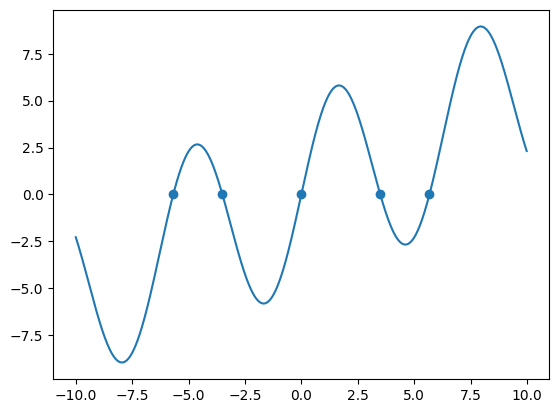

In [20]:
f = lambda x : 5 * np.sin(x) + x/2
df = lambda x : 5 * np.cos(x) + 1/2

crossings = findAllZeroCrossings(f, df, [-10,10], 0.5)
t = np.arange(-10,10,0.01)
plt.plot(t, f(t))
plt.scatter(crossings, [0 for _ in range(len(crossings))])